<a href="https://colab.research.google.com/github/bforoura/ML26/blob/main/Module8_Unsupervised/customer_segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Unsupervised Learning: Customer Segmentation with K-Means, DBSCAN, and HDBSCAN**


* Here, we explore **unsupervised machine learning techniques**, focusing on clustering algorithms and validation metrics.

* Using the **Mall Customer Segmentation Dataset**, we demonstrate how businesses use unsupervised techniques to group customers based on demographic and purchasing attributes without pre-existing labels.

* In addition to traditional methods like **K-Means** and **DBSCAN**, **HDBSCAN (Hierarchical Density-Based Spatial Clustering of Applications with Noise)** is introduced to address variable-density clusters and parameter sensitivity.



# **Covered Topics**
1. **Exploratory Data Analysis & Preprocessing**
   * Data cleaning, visualization, and feature scaling.

2. **K-Means Clustering**
   * Fitting models, visualizing cluster decision boundaries, and extracting centroids.
   * Hard vs. Soft Clustering (distance-based feature space transformation).

3. **Cluster Evaluation Methods**
   * Evaluating cluster quality using Inertia (the **Elbow Method**).
   * Measuring silhouette metrics and constructing Silhouette Diagrams.

4. **Limitations of K-Means & Density-Based Approaches**
   * Understanding K-Means failure modes (non-spherical shapes, outliers, fixed variance assumptions).
   * Introduction to DBSCAN (Core points, Border points, Noise/Outliers).

5. **HDBSCAN**
   * Overcoming DBSCAN's global epsilon limitation using hierarchical density-based clustering.
   * Comparing clustering performance across algorithms on real-world data.


# **Mall Customer Segmentation Dataset**

* Source: Mall Customer Dataset (Kaggle / Public Repository)

* Features:
  * **CustomerID**: Unique identifier for each customer.
  * **Gender**: Gender of the customer.
  * **Age**: Age of the customer.
  * **Annual Income** (k$): Annual income of the customer in thousands of dollars.
  * **Spending Score** (1-100): Score assigned by the mall based on customer behavior and spending nature.

  
  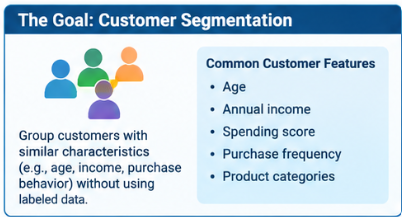


  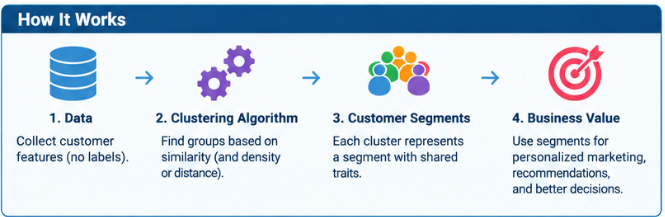

# **Section 1: Setup, Data Loading, and Exploratory Data Analysis**

* Let's first import the required Python libraries for data manipulation, visualization, and clustering.

* Then, load the Mall Customer Segmentation dataset from a public source.

* Inspect the set's basic structure, check for missing values, and visualize the relationship between **Annual Income** and **Spending Score** to understand natural customer groupings.

Dataset Head:


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Summary Statistics:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


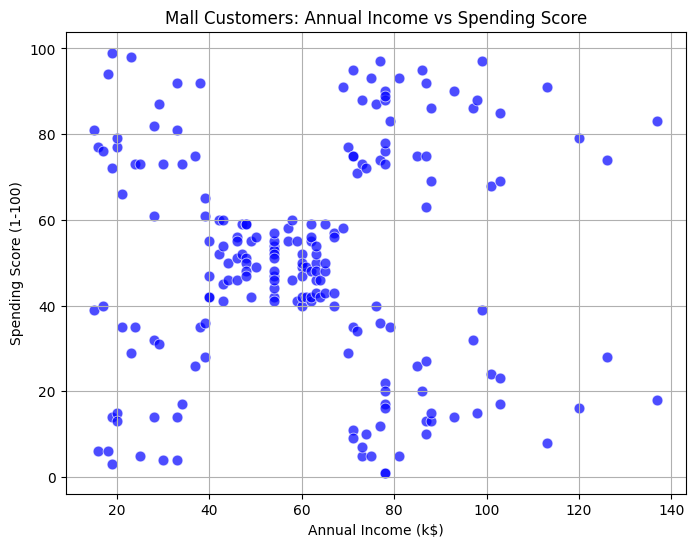

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Mall Customer Segmentation dataset from a verified public GitHub repository
url = "https://raw.githubusercontent.com/krishnaik06/DBSCAN-Algorithm/master/Mall_Customers.csv"
df = pd.read_csv(url)

# Display the first few rows of the dataset
print("Dataset Head:")
display(df.head())

# Display basic information and check for missing values
print("\nDataset Info:")
df.info()

# Display summary statistics of numerical features
print("\nSummary Statistics:")
display(df.describe())

# Visualize the relationship between Annual Income and Spending Score
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    data=df,
    s=60,
    color='blue',
    alpha=0.7
)
plt.title('Mall Customers: Annual Income vs Spending Score')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.grid(True)
plt.show()

# **Explanation of the Output**

* The generated scatter plot visualizes the unlabelled Mall Customer dataset by plotting **Annual Income ($k$)** on the horizontal axis against the **Spending Score (1-100)** on the vertical axis.

* Identified clusters:
   * clusters with lower incomes and varying spending scores
   * a central cluster with moderate income and moderate spending
   * clusters with higher incomes split between high and low spending scores


* Because there are no pre-existing class labels ($y$), this visual structure demonstrates why automated learners such as **K-Means or DBSCAN** are needed to discover these customer segments using **similarity measures**.

* The plot shows varying densities and potential outliers across the feature space, highlighting why **standard clustering assumptions such as spherical clusters of equal variance** can face challenges but more advanced algorithms like **DBSCAN or HDBSCAN can address**.

# **Section 2: K-Means Clustering and Centroid Visualization**

* Let's apply the K-Means clustering algorithm to the customer dataset.

* We first need to **scale our numerical features because K-Means relies entirely on distance calculations**.

* We then specify $k=5$ clusters, fit the model, extract the resulting cluster centroids.

* Finally, plot the cluster assignments along with their decision boundaries known as **Voronoi regions**.

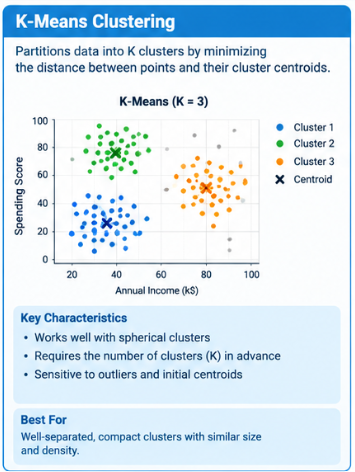

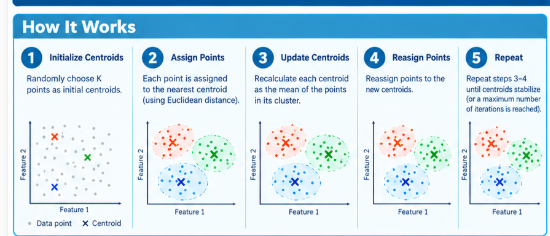

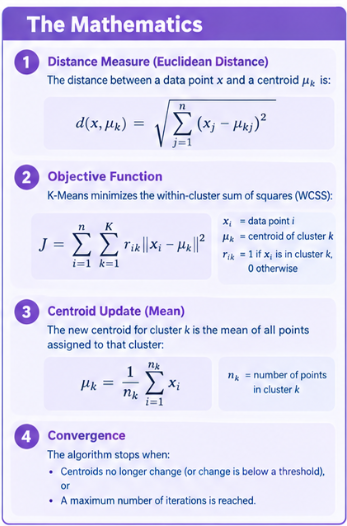

Cluster Centers (Original Scale - Annual Income, Spending Score):
[[55.2962963  49.51851852]
 [86.53846154 82.12820513]
 [25.72727273 79.36363636]
 [88.2        17.11428571]
 [26.30434783 20.91304348]]


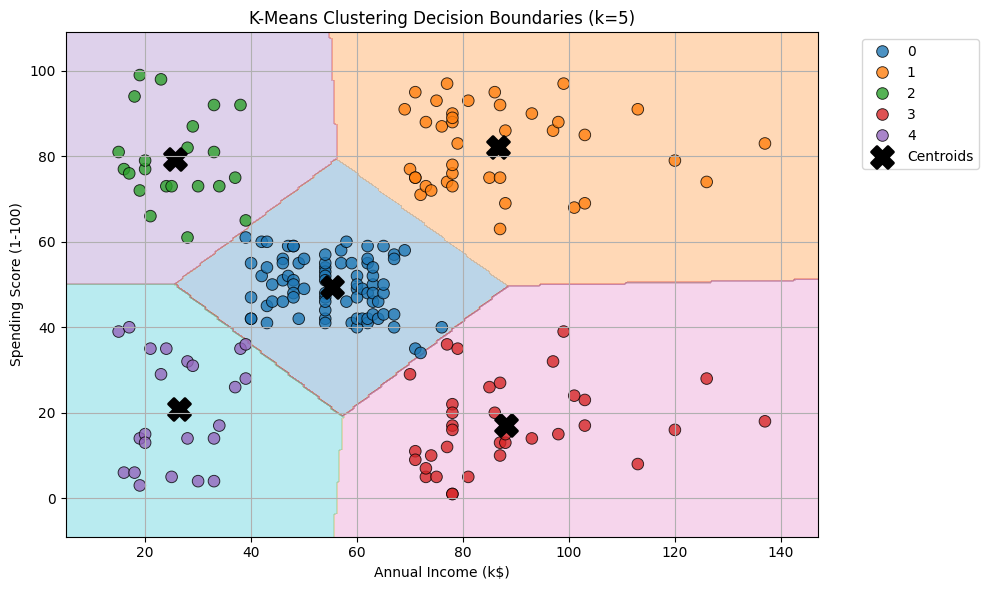

In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Select features for clustering
X = df[['Annual Income (k$)', 'Spending Score (1-100)']].values

# Feature scaling (essential for K-Means distance metrics)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Instantiate and fit K-Means with k=5
k = 5
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
y_pred = kmeans.fit_predict(X_scaled)

# Add cluster labels to the dataframe
df['Cluster'] = y_pred

# Extract cluster centers and inverse transform back to original scale
centroids_scaled = kmeans.cluster_centers_
centroids = scaler.inverse_transform(centroids_scaled)

print("Cluster Centers (Original Scale - Annual Income, Spending Score):")
print(centroids)

# Plotting decision boundaries, data points, and centroids
plt.figure(figsize=(10, 6))

# Create a mesh grid to plot decision boundaries (Voronoi regions)
x_min, x_max = X[:, 0].min() - 10, X[:, 0].max() + 10
y_min, y_max = X[:, 1].min() - 10, X[:, 1].max() + 10
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))

# Predict cluster for each point in the mesh grid
grid_points = np.c_[xx.ravel(), yy.ravel()]
grid_points_scaled = scaler.transform(grid_points)
Z = kmeans.predict(grid_points_scaled)
Z = Z.reshape(xx.shape)

# Plot the decision boundaries using contour regions
plt.contourf(xx, yy, Z, alpha=0.3, cmap='tab10')

# Plot the customer data points colored by their assigned cluster
sns.scatterplot(
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    data=df,
    palette='tab10',
    s=70,
    alpha=0.8,
    edgecolor='k'
)

# Plot the centroids
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker='X',
    s=250,
    linewidths=2,
    color='black',
    label='Centroids'
)

plt.title('K-Means Clustering Decision Boundaries (k=5)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

# **Explanation of the Output**

* The background is partitioned into five distinct colored regions representing the decision boundaries.

* Every point in a given region is closer to that specific cluster's centroid than to any other centroid, illustrating K-Means' strict distance-based partitioning.

* The large black `X` marks indicate the final coordinates of the five cluster centers after the algorithm converged.

* **Customer Segments:**
   * **Cluster 0 (Blue - Center):** Moderate annual income and moderate spending score.
   * **Cluster 1 (Orange - Top Right):** High annual income and high spending score (high-value target customers).
   * **Cluster 2 (Green - Top Left):** Low annual income and high spending score.
   * **Cluster 3 (Red - Bottom Right):** High annual income and low spending score (conservative spenders).
   * **Cluster 4 (Purple - Bottom Left):** Low annual income and low spending score.

# **Section 3: Hard vs. Soft Clustering and Distance Transformations**

* The difference between **hard clustering** and **soft clustering**:

  * **hard clustering assigns each customer to a single definitive cluster**
  * **soft clustering evaluates scoring across all clusters based on distance metrics**.

* We can use the **trained K-Means** model to compute distance transformations for new or existing customer data

* This will show how these distances can serve as an **efficient dimensionality reduction technique**.

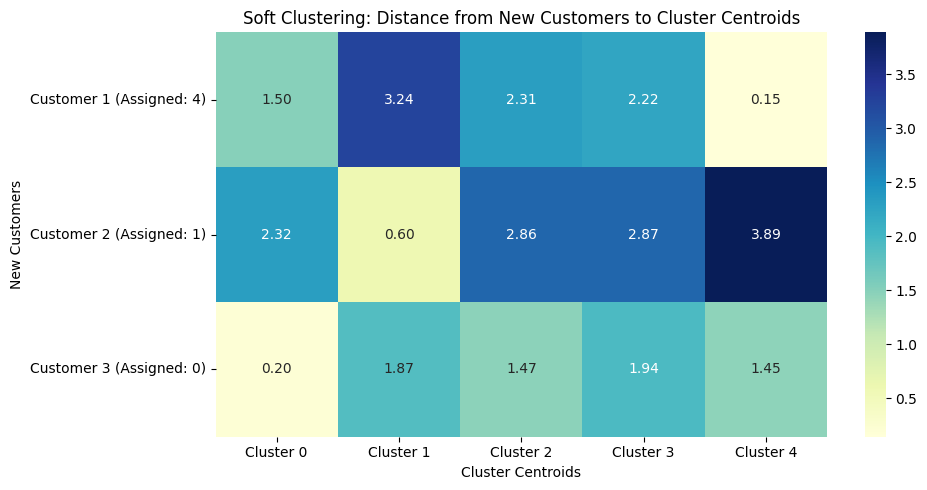

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Define new customer points (Annual Income, Spending Score)
X_new = np.array([
    [30, 20],   # Low income, low spending
    [100, 90],  # High income, high spending
    [50, 50]    # Moderate income, moderate spending
])

# Scale the new points using the fitted scaler
X_new_scaled = scaler.transform(X_new)

# Compute distances from each new point to all k centroids
distances = kmeans.transform(X_new_scaled)

# Hard clustering prediction for these new points
new_predictions = kmeans.predict(X_new_scaled)

# Visualize distances using a heatmap
plt.figure(figsize=(10, 5))
sns.heatmap(
    distances,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    xticklabels=[f"Cluster {i}" for i in range(k)],
    yticklabels=[f"Customer {i+1} (Assigned: {pred})" for i, pred in enumerate(new_predictions)]
)
plt.title("Soft Clustering: Distance from New Customers to Cluster Centroids")
plt.xlabel("Cluster Centroids")
plt.ylabel("New Customers")
plt.tight_layout()
plt.show()

# **Explanation of the Output**

* The above heatmap visualizes the distance transformation (**soft clustering output**) produced by the **K-Means** `.transform()` method for **three new customer data points** across all five cluster centroids.



* **Customer 1 (Assigned to Cluster 4):** Looking at the first row, the smallest distance is $0.15$, which corresponds to **Cluster 4**. This confirms why the hard clustering assignment for Customer 1 is Cluster 4.
   
* **Customer 2 (Assigned to Cluster 1):** In the second row, the minimum distance is $0.60$, located at **Cluster 1**, making it the definitive hard assignment.
  
* **Customer 3 (Assigned to Cluster 0):** For the third row, the smallest distance is $0.20$ at **Cluster 0**, leading to a hard assignment of Cluster 0.

<br>

**Dimensionality Reduction & Soft Clustering Insight:**
   * Instead of reducing each customer to a single discrete label, the transformation maps each data point into a $5$-dimensional distance vector.
   * This profile of distances indicates not just *where* a point belongs, but *how close* it is to alternative segments, showing the transition from hard assignment to soft probability-like affinity.

# **Section 4: Choosing the Optimal Number of Clusters (Elbow Method & Silhouette Scores)**

* Because **K-Means requires specifying the number of clusters $k$ in advance**, selecting the right value is a critical challenge.

* Here, we implement two standard evaluation techniques discussed in the lecture:

  1. **The Elbow Method (Inertia):** Calculate the total **intra-cluster variance (inertia)** for different values of $k$ and look for an **elbow** point where adding more clusters yields diminishing returns.

  2. **The Silhouette Score:** Compute the **mean silhouette coefficient** across instances for various $k$ values to measure cluster cohesion and separation, providing a more precise evaluation of optimal cluster count.

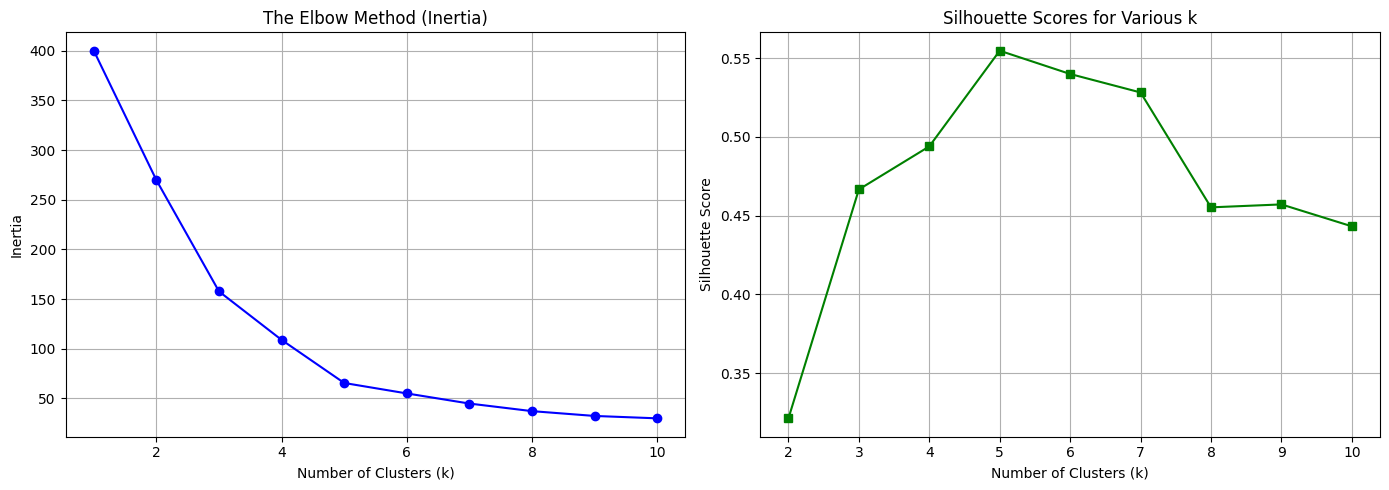

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

inertia = []
silhouette_scores = []
K_range = range(2, 11)

# Calculate inertia for k from 1 to 10
for k in range(1, 11):
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_temp.fit(X_scaled)
    inertia.append(kmeans_temp.inertia_)

# Calculate silhouette score for k from 2 to 10
for k in K_range:
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans_temp.fit_predict(X_scaled)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

# Plotting Elbow Method and Silhouette Scores side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Elbow Method Plot
ax1.plot(range(1, 11), inertia, marker='o', color='b', linestyle='-')
ax1.set_title('The Elbow Method (Inertia)')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia')
ax1.grid(True)

# Silhouette Score Plot
ax2.plot(K_range, silhouette_scores, marker='s', color='g', linestyle='-')
ax2.set_title('Silhouette Scores for Various k')
ax2.set_xlabel('Number of Clusters (k)')
ax2.set_ylabel('Silhouette Score')
ax2.grid(True)

plt.tight_layout()
plt.show()

# **Explanation of the Output**

1. **The Elbow Method**
   * **Inertia** measures the **total within-cluster sum of squared errors**  
   * This represents how tightly bound the data points are around their respective cluster centroids.
   * As  $k$ increases, inertia decreases because **smaller clusters have less internal dispersion**.
   * Beyond k=5, adding more clusters does not result in more variance reduction.
   * This suggests that $k = 5$ is an optimal choice from a cost-minimization perspective.

<br>

2. **Silhouette Scores Plot**

   * This measures how similar a point is to its own cluster compared to other  clusters, resulting in a score ranging from -1 to +1
   * Note that higher scores indicate better-defined and well-separated clusters.

   * The silhouette score reaches its absolute maximum peak at $k = 5$ or approx. 0.55.
   * This indicates that clustering the data into five groups provides the strongest cluster separation.


<br>

**Note:**

* Both evaluations consistently point to $k = 5$ as the optimal number of clusters for this dataset.

# **Section 5: DBSCAN Clustering and Noise Identification**

* Let's now **transition from centroid-based models to density-based clustering** using **DBSCAN (Density-Based Spatial Clustering of Applications with Noise)**.

* **Unlike K-Means**, **DBSCAN** does not require us to pre-specify the number of clusters $k$.

* Instead, it groups together points that are closely packed together, marking points that lie alone in low-density regions as outliers or noise.

* Two key hyperparameters:
  * **`eps`** is the maximum distance between two samples for one to be considered as in the neighborhood of the other
  *  **`min_samples`** is the number of samples in a neighborhood for a point to be considered as a core point.

  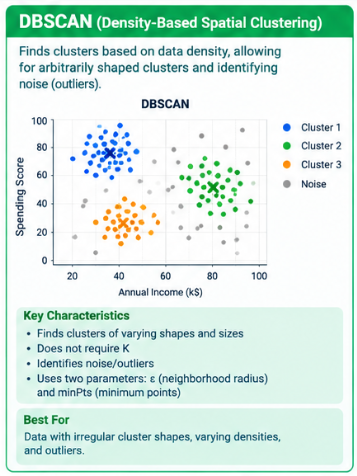

  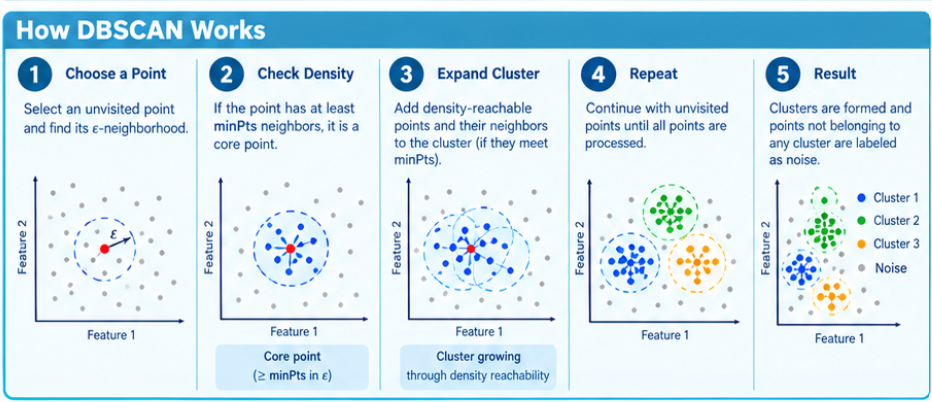

  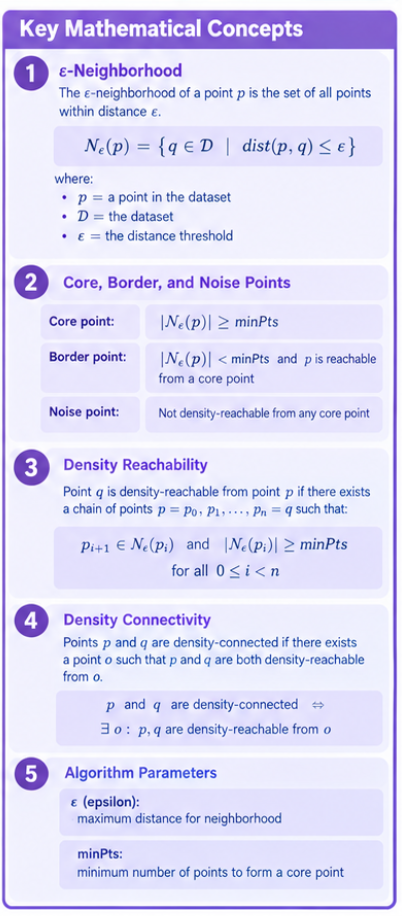

Estimated number of clusters: 2
Estimated number of noise points: 8


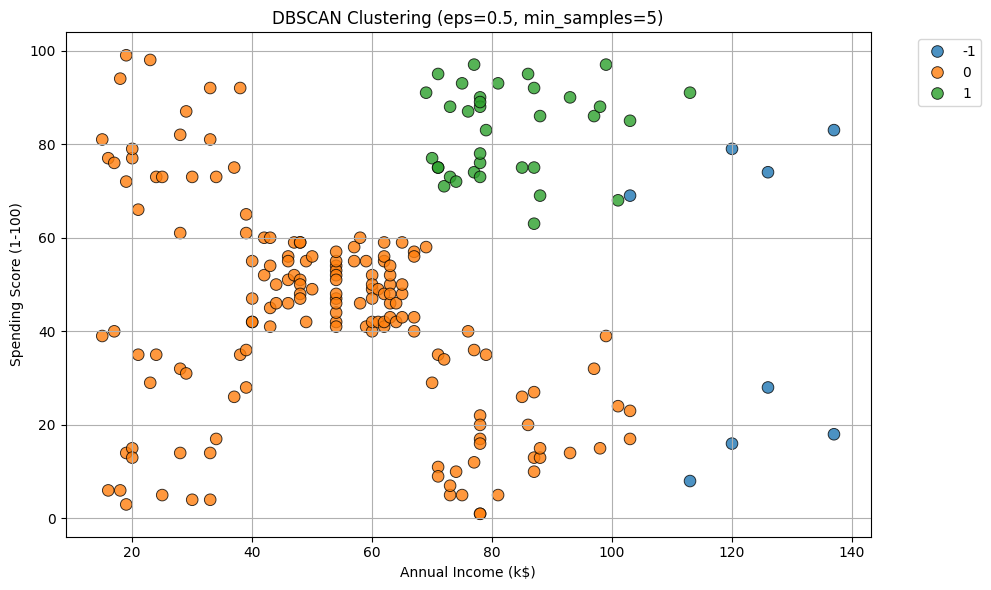

In [ ]:
from sklearn.cluster import DBSCAN

# Instantiate and fit DBSCAN on scaled features
dbscan = DBSCAN(eps=0.5, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)

# Add DBSCAN labels to the dataframe
df['DBSCAN_Cluster'] = dbscan_labels

# Count clusters and noise points (-1 represents noise points)
n_clusters_ = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise_ = list(dbscan_labels).count(-1)

print(f"Estimated number of clusters: {n_clusters_}")
print(f"Estimated number of noise points: {n_noise_}")

# Visualize DBSCAN clustering results
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='DBSCAN_Cluster',
    data=df,
    palette='tab10',
    s=70,
    alpha=0.8,
    edgecolor='k',
    legend='full'
)
plt.title('DBSCAN Clustering (eps=0.5, min_samples=5)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

# **Explanation of the Output**

* Unlike K-Means, which forced $k=5$ rigid partitions, DBSCAN grouped the dense regions differently.

* Here, it identified two primary dense clusters labeled as **Cluster 0** in orange and **Cluster 1** in green.

* The points colored in blue (labeled as `-1` in the legend) represent **noise/outliers**

* These are points that do not belong to any dense neighborhood according to the specified **eps** and **min_samples** parameters, meaning they are **left unassigned rather than forced into a cluster**.

<br>

**Notes**
 * K-Means requires we define the number of clusters $k$ beforehand, whereas DBSCAN automatically discovers the number of clusters based on density parameters.

 * **K-Means** forces **every single data point** into one of the $k$ clusters which can distort centroids if outliers are present.

 * **DBSCAN** explicitly detects and isolates outliers as noise (`-1`), preventing them from contaminating valid clusters.

 * **K-Means assumes spherical, convex clusters of similar size** because it relies on mean centroids and Euclidean distance partitioning.

 * **DBSCAN can find arbitrarily shaped clusters** such as rings, crescents, or elongated densities as long as they are connected by continuous high-density regions.

# **Section 6: HDBSCAN Clustering (Hierarchical Density-Based Spatial Clustering)**

* Finally, let's implement **HDBSCAN (Hierarchical Density-Based Spatial Clustering of Applications with Noise)**.

* While standard **DBSCAN is powerful, it struggles with data containing varying densities across different clusters**.

* **HDBSCAN extends DBSCAN** by converting it into a **hierarchical clustering** algorithm and then using a stability-based technique to extract the most persistent clusters.

* This eliminates the strict global $\epsilon$ sensitivity of standard DBSCAN while continuing to isolate noise effectively.


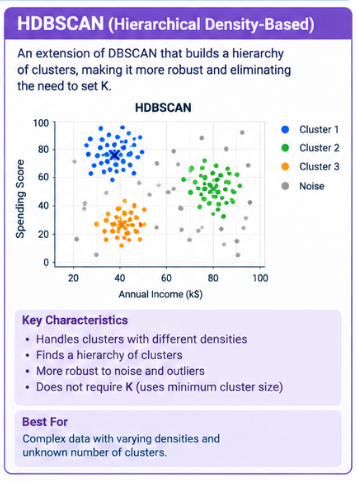

Estimated number of HDBSCAN clusters: 6
Estimated number of HDBSCAN noise points: 27


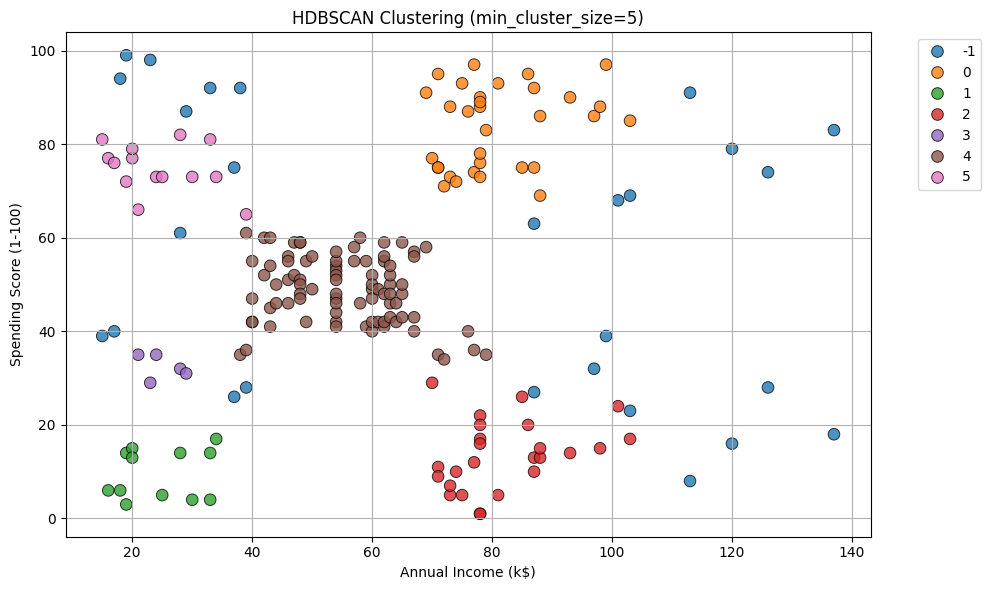

In [ ]:
from sklearn.cluster import HDBSCAN

# Instantiate and fit HDBSCAN on scaled features
hdbscan_model = HDBSCAN(min_cluster_size=5)
hdbscan_labels = hdbscan_model.fit_predict(X_scaled)

# Add HDBSCAN labels to the dataframe
df['HDBSCAN_Cluster'] = hdbscan_labels

# Count clusters and noise points (-1 represents noise points)
n_hdbscan_clusters_ = len(set(hdbscan_labels)) - (1 if -1 in hdbscan_labels else 0)
n_hdbscan_noise_ = list(hdbscan_labels).count(-1)

print(f"Estimated number of HDBSCAN clusters: {n_hdbscan_clusters_}")
print(f"Estimated number of HDBSCAN noise points: {n_hdbscan_noise_}")

# Visualize HDBSCAN clustering results
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='HDBSCAN_Cluster',
    data=df,
    palette='tab10',
    s=70,
    alpha=0.8,
    edgecolor='k',
    legend='full'
)
plt.title('HDBSCAN Clustering (min_cluster_size=5)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

# **Explanation of the Output**

* **HDBSCAN** identifies multiple distinct **clusters (labeled 0 through 5)**across the feature space by building a cluster hierarchy and selecting clusters based on stability over varying scales.


* Points marked in blue with the label `-1` represent outliers and boundary noise that do not belong stably to any persistent cluster.


* **K-Means**
   * requires an explicit $k$ value (we used $k=5$), whereas HDBSCAN automatically determines the number of clusters based on density and hierarchy.
  
   * enforces spherical, centroid-Voronoi partitions. HDBSCAN makes no assumptions about shape and can uncover complex structural groupings.

   * forces every single data point into a cluster, which distorts centroids. HDBSCAN explicitly labels outliers as noise (`-1`).

* **DBSCAN** relies heavily on a single global $\epsilon$ parameter to define neighborhood distances, making it vulnerable when clusters have varying densities.

* **HDBSCAN** handles clusters of varying densities by converting DBSCAN into a hierarchical framework and extracting clusters based on their persistence/stability over multiple thresholds, avoiding the limitations of a fixed global radius.

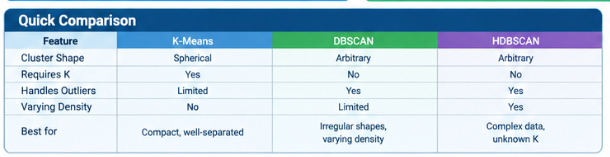

# **Section 7: Visualizing the HDBSCAN Hierarchy (Condensed Tree)**

* To better understand how **HDBSCAN** builds its hierarchy and extracts clusters, we can visualize the condensed cluster tree.

* Unlike standard hierarchical clustering dendrograms, **HDBSCAN** collapses branches to show only the clusters that persist stably over multiple density thresholds.

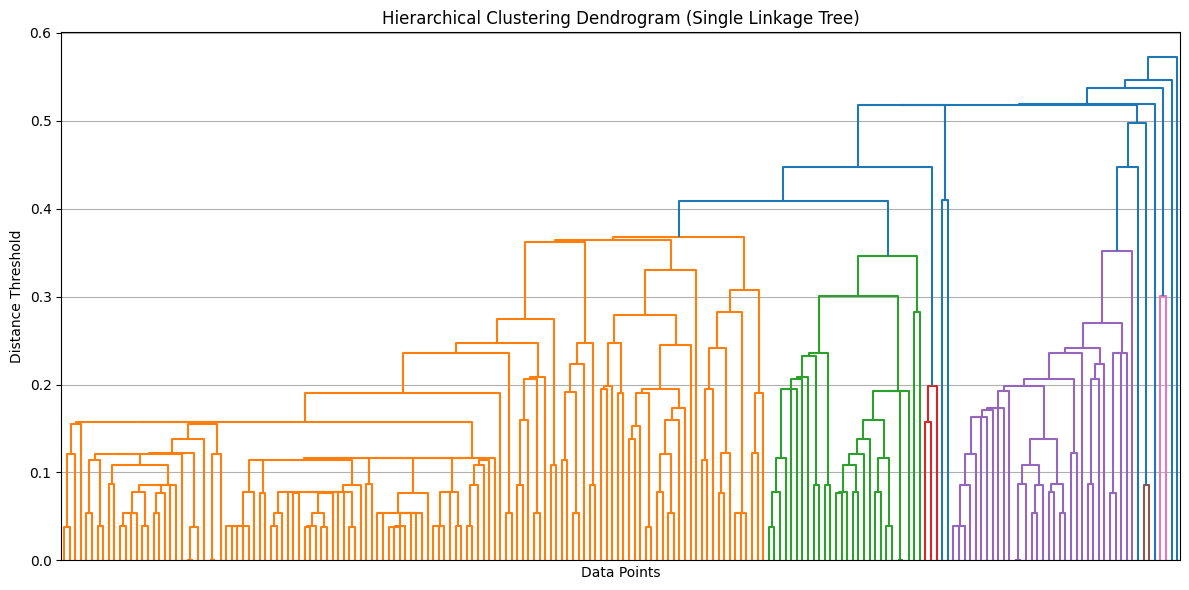

In [ ]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
import numpy as np

# Compute the linkage matrix using Ward's method or single linkage on scaled data
# to illustrate the hierarchical tree structure
linked = linkage(X_scaled, method='single')

plt.figure(figsize=(12, 6))
dendrogram(
    linked,
    orientation='top',
    distance_sort='descending',
    show_leaf_counts=False,
    no_labels=True
)

plt.title('Hierarchical Clustering Dendrogram (Single Linkage Tree)')
plt.xlabel('Data Points')
plt.ylabel('Distance Threshold')
plt.grid(True)
plt.tight_layout()
plt.show()

# **Explanation of the Output**


* The above **dendrogram** visualizes the hierarchical merging of data points across varying distance thresholds:

  * **X-Axis (Data Points):** Individual customer samples represented at the base.
  * **Y-Axis (Distance Threshold):** The linkage distance at which clusters merge. Taller vertical branches indicate more distinct, well-separated cluster combinations.
  * **Tree Structure & Branching:** Starting from individual points at the bottom ($0.0$), branches join progressively higher up as distance thresholds increase. HDBSCAN builds upon this hierarchical tree concept, evaluating stability across different height cuts to extract persistent clusters while isolating noise.